# Generate images

In [31]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler


#%% Loading the data
df = pd.read_csv("dataset.csv")

# Control NaN values
df = df.drop(columns = ['src_ip', 'Label'], axis = 1) 

# Function to replace -inf with the minimum value or 0 if only NaNs
def replace_negative_inf(df):
    for column in df.columns:
        min_value = df[column][df[column] != -np.inf].min()
        if pd.isna(min_value):
            min_value = 0
        df[column] = df[column].replace(-np.inf, min_value)
        #df[column].fillna(min_value, inplace=True)
    return df

# Function to replace NaN and inf with the maximum value or 1 if only zeros
def replace_inf(df):
    for column in df.columns:
        max_value = df[column][df[column] != np.inf].max()
        if pd.isna(max_value) or max_value == 0:
            max_value = 1
        df[column] = df[column].replace(np.inf, max_value)
        # df[column].fillna(max_value, inplace=True)
    return df

for column in df.columns:
    df[column].fillna(0, inplace=True)

# Apply the functions to replace values
df = replace_negative_inf(df)
df = replace_inf(df)

C:\Users\ariel\AppData\Local\Temp\ipykernel_26748\2579916773.py:33: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[column].fillna(0, inplace=True)


In [32]:

scaler = MinMaxScaler()
df_scaled = pd.DataFrame(scaler.fit_transform(df), columns=df.columns)

In [33]:
import os
import numpy as np
from scipy.stats import pearsonr

# Check if the file exists
if os.path.exists('vfp/sorted_indices_vfp.txt'):
    # Read the sorted indices from the file
    with open('vfp/sorted_indices_vfp.txt', 'r') as file:
        sorted_indices_desc = np.array([int(line.strip()) for line in file.readlines()])
else:
    # Step 1 & 2: Calculate PCCs and sum them for each attribute
    pcc_sums = np.array([sum([pearsonr(df[col], df[other_col])[0] for other_col in df.columns if other_col != col]) for col in df.columns])

    # Step 3: Sort attributes by PCC sums
    sorted_indices_asc = np.argsort(pcc_sums)
    sorted_indices_desc = sorted_indices_asc[::-1]  # Assuming combined_features_sorted is this

    # Ensure the directory exists
    os.makedirs('vfp', exist_ok=True)
    # Write the sorted indices to the file
    with open('vfp/sorted_indices_vfp.txt', 'w') as file:
        for index in sorted_indices_desc:
            file.write(f"{index}\n")

C:\Users\ariel\AppData\Local\Temp\ipykernel_26748\3444838292.py:12: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  pcc_sums = np.array([sum([pearsonr(df[col], df[other_col])[0] for other_col in df.columns if other_col != col]) for col in df.columns])


In [34]:
import numpy as np

def arrange_in_vortex(row, indices, image_size):
    # Create an empty matrix for the single-channel image
    image = np.zeros((image_size, image_size))
    # Adjusting for a counterclockwise spiral starting from the center
    center = image_size // 2
    x, y = center, center
    dx, dy = 0, -1  # Adjust initial direction for counterclockwise spiral
    step_size = 1
    steps_count = 0
    change_direction_steps = 1
    direction_changes = 0  # Track the number of direction changes

    for i in range(len(indices)):
        # Check if the current position is within bounds
        if 0 <= x < image_size and 0 <= y < image_size:
            # Access the row by column index
            image[x, y] = row.iloc[indices[i]] * 255
        steps_count += 1
        if steps_count == change_direction_steps:
            steps_count = 0
            direction_changes += 1
            # Change direction
            dx, dy = -dy, dx
            # Increase step size after every two direction changes
            if direction_changes % 2 == 0:
                change_direction_steps += 1

        x, y = x + dx, y + dy

    return image


Index: 0


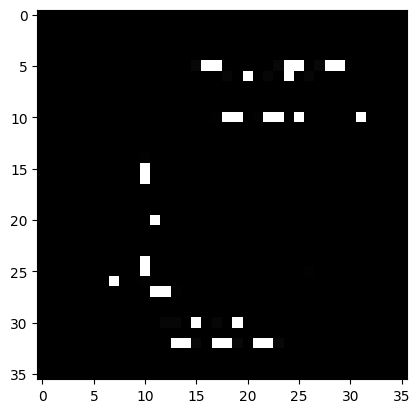

Index: 100


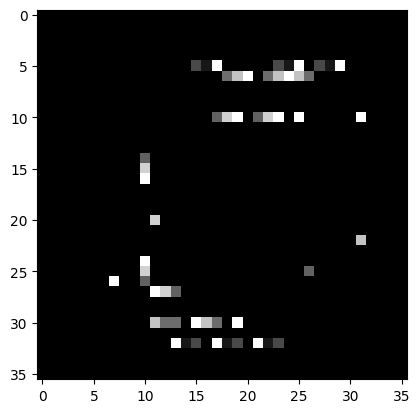

Index: 200


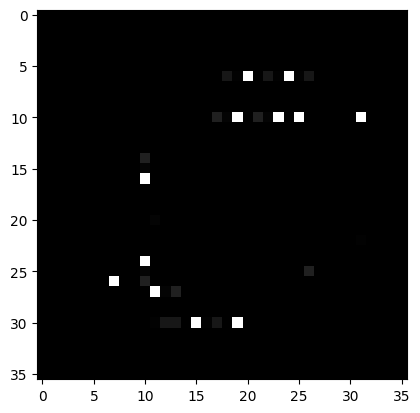

Index: 300


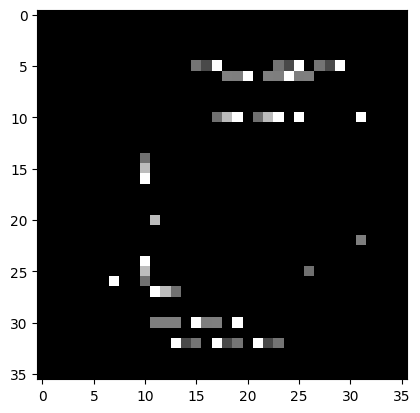

Index: 400


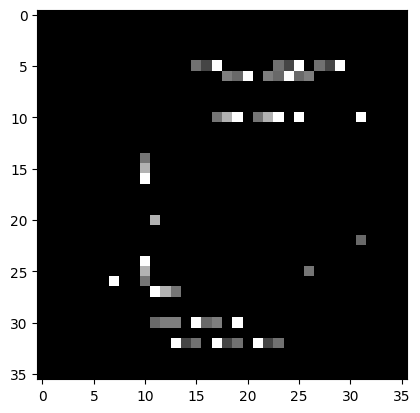

In [35]:

import numpy as np
import pandas as pd
from scipy.stats import pearsonr
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler



# Step 4: Generate images and print index and image if index % 40 is 0
image_size = 36  # Example size, adjust as needed
images = [] 
for index, row in df.iterrows():
    image = arrange_in_vortex(row, sorted_indices_desc, image_size)
    images.append(image)
    if index % 100 == 0:
        print(f"Index: {index}")
        plt.imshow(image, cmap='gray')
        plt.show()

images = np.array(images)

# Step 5: Replicate the single-channel images across three channels
images_rgb = np.repeat(images[..., np.newaxis], 3, -1)

# Normalize images
scaler = MinMaxScaler()
images_rgb = scaler.fit_transform(images_rgb.reshape(-1, images_rgb.shape[-1])).reshape(images_rgb.shape)

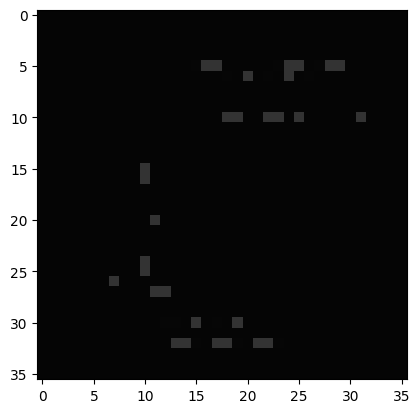

In [36]:

# Example: Show the first image
plt.imshow(images_rgb[0], cmap='gray')
plt.show()

In [37]:
images_rgb[0].shape

(36, 36, 3)

In [38]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df2 = pd.read_csv("dataset.csv")

# Change label from 'Suspicious' to 'Critical'
df2["Label"] = df2["Label"].apply(lambda x: "Critical" if x == "Suspicious" else x) 


if os.path.exists('vfp/img') and os.listdir('vfp/img'):
    print("Directory is not empty. Exiting...")
else:
    for index, row in df2.iterrows():
        label = row['Label']
        src_ip = row['src_ip']
        image = images_rgb[index]

        # Create directory if it doesn't exist
        directory = f"vfp/img/{label}"
        if not os.path.exists(directory):
            os.makedirs(directory)
        
        # Save the image using plt.imsave
        file_path = os.path.join(directory, f"{src_ip}.png")
        plt.imsave(file_path, image)

    print("Images saved successfully.")


Images saved successfully.


# Run training

## Fitting a CNN Model

In [39]:
import torch
import torch.nn as nn
import torchvision.transforms as transforms
from torch.utils.data import TensorDataset, DataLoader
import torch.optim as optim
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
import torch.nn.functional as F

In [40]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=8):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)
        # Reduced pooling size to preserve more information
        self.pool = nn.MaxPool2d(2, 2)
        self.dropout1 = nn.Dropout(0.25)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.dropout2 = nn.Dropout(0.25)
        # Additional convolutional layer to capture more complex patterns
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.dropout3 = nn.Dropout(0.25)
        # Batch normalization to stabilize learning
        self.bn1 = nn.BatchNorm2d(16)
        self.bn2 = nn.BatchNorm2d(32)
        self.bn3 = nn.BatchNorm2d(64)
        # Adjusted for an additional pooling layer, resulting in 36/2/2/2 = 4.5 ~ 4 (floor) for the size of feature maps
        self.fc1 = nn.Linear(64 * 4 * 4, 256)  # Adjusted for added complexity and reduced pooling effect
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.dropout1(x)
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = self.dropout2(x)
        x = self.pool(F.relu(self.bn3(self.conv3(x))))  # Additional pooling layer for the new conv layer
        x = self.dropout3(x)
        x = x.view(x.size(0), -1)  # Flatten the tensor for the fully connected layer
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

In [41]:
import numpy as np
from sklearn.model_selection import train_test_split

y = df2["Label"]
 
X_train, X_test, y_train, y_test = train_test_split(images_rgb, y, test_size=0.2, random_state=42)

In [42]:
from sklearn.preprocessing import LabelEncoder
from collections import Counter
# from sklearn.model_selection import train_test_split
import numpy as np

#y = df["Label"]
# Add stratify=y to ensure the same distribution of classes in both sets
#X_train, X_test, y_train, y_test = train_test_split(X_REFINED_MDS, y, test_size=0.2, random_state=42, stratify=y)

#y_train = y_train.values
#y_test = y_test.values

le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)
num_classes = np.unique(y_train_enc).size

print(Counter(y_train_enc))
print(Counter(y_test_enc))

Counter({0: 170, 1: 162})
Counter({0: 55, 1: 29})


In [43]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)
preprocess = transforms.Compose([
    transforms.ToTensor()
])
X_train_tensor = torch.tensor(X_train[:,:,:,0], dtype=torch.float).unsqueeze(1)  # Selects the first channel and adds a channel dimension
y_train_tensor = torch.from_numpy(le.fit_transform(y_train))

X_test_tensor = torch.tensor(X_test[:,:,:,0], dtype=torch.float).unsqueeze(1)  # Selects the first channel and adds a channel dimension
y_test_tensor = torch.from_numpy(le.transform(y_test))

cuda


In [44]:
batch_size = 32

trainset = TensorDataset(X_train_tensor, y_train_tensor)
trainloader = DataLoader(trainset, batch_size=batch_size, shuffle=True)

testset = TensorDataset(X_test_tensor, y_test_tensor)
testloader = DataLoader(testset, batch_size=batch_size, shuffle=False)

In [45]:
model = SimpleCNN(num_classes=num_classes).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(
    model.parameters(),
    lr=1e-03,
    weight_decay=1e-05
)

In [46]:
model.train()
model.to(device)
for epoch in range(100):

    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # get the inputs; data is a list of [inputs, labels]
        inputs, labels = data
        inputs = inputs.to(device)
        labels = labels.to(device).long()

        outputs = model(inputs)
        loss = criterion(outputs, labels)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
    # print epoch statistics
    if not (epoch % 20):
        print(f'[{epoch}] loss: {running_loss / len(X_train_tensor) * batch_size:.3f}')
print(f'[{epoch}] loss: {running_loss / len(X_train_tensor) * batch_size:.3f}')

[0] loss: 0.960
[20] loss: 0.676
[40] loss: 0.607
[60] loss: 0.642
[80] loss: 0.612
[99] loss: 0.618


In [47]:
model.to('cpu')
model = model.eval()
with torch.no_grad():
    y_hat = model(X_train_tensor)
train_predicted = torch.max(y_hat, 1)[1]
with torch.no_grad():
    y_hat = model(X_test_tensor)
test_predicted = torch.max(y_hat, 1)[1]
print(f"The train accuracy was {accuracy_score(train_predicted, y_train_tensor):.3f}")
print(f"The test accuracy was {accuracy_score(test_predicted, y_test_tensor):.3f}")

The train accuracy was 0.687
The test accuracy was 0.643


In [48]:
from sklearn.metrics import f1_score, recall_score

# Calculate F1 score
f1 = f1_score(y_test_tensor, test_predicted, average='weighted')  # Use 'binary' for binary classification, 'weighted' for multi-class

# Calculate Recall
recall = recall_score(y_test_tensor, test_predicted, average='weighted')  # Use 'binary' for binary classification, 'weighted' for multi-class

print(f"F1 Score: {f1}")
print(f"Recall: {recall}")

F1 Score: 0.6492960164835165
Recall: 0.6428571428571429


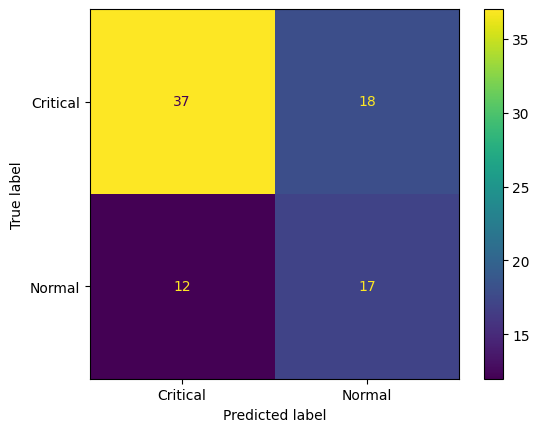

In [49]:
_ = ConfusionMatrixDisplay.from_predictions(y_test_tensor, test_predicted, display_labels=le.classes_)

## Fastai

In [50]:
from fastai.vision.all import *
from sklearn.model_selection import train_test_split

def balanced_splitter(files, valid_pct=0.2, seed=42):
    # Get labels
    labels = [parent_label(f) for f in files]
    
    # Split each class individually and collect train/valid indices
    train_idxs, valid_idxs = [], []
    for cls in set(labels):
        # Indices for current class
        cls_idxs = [i for i, x in enumerate(labels) if x == cls]
        
        # Split indices for the current class
        cls_train_idxs, cls_valid_idxs = train_test_split(cls_idxs, test_size=valid_pct, random_state=seed)
        
        # Append current class indices to the main lists
        train_idxs.extend(cls_train_idxs)
        valid_idxs.extend(cls_valid_idxs)
    
    return train_idxs, valid_idxs

In [51]:
from fastai.vision.all import *

# Step 1: Define the DataBlock
datablock = DataBlock(
    blocks=(ImageBlock, CategoryBlock), 
    get_items=get_image_files, 
    splitter=RandomSplitter(valid_pct=0.2, seed=42),
    get_y=parent_label,
    item_tfms=Resize(36)  # Resize images to 36x36 if necessary
)

# Step 2: Create a DataLoader
dls = datablock.dataloaders('vfp/img')


## Resnet 18

In [52]:

# Step 3: Load a Pretrained ResNet18 Model
learn = cnn_learner(dls, resnet18, metrics=accuracy)

# Step 4: Train the Model
learn.fit_one_cycle(25)

c:\Python312\Lib\site-packages\fastai\vision\learner.py:301: UserWarning: `cnn_learner` has been renamed to `vision_learner` -- please update your code
  warn("`cnn_learner` has been renamed to `vision_learner` -- please update your code")


epoch,train_loss,valid_loss,accuracy,time
0,1.178961,0.699288,0.469880,00:03
1,1.078659,0.861390,0.481928,00:00
2,1.018545,0.829938,0.554217,00:00
3,0.959170,1.443164,0.590361,00:00
4,0.914916,1.753067,0.566265,00:00
5,0.879133,1.232377,0.590361,00:00
6,0.853384,0.747440,0.674699,00:00
7,0.824302,0.786665,0.686747,00:00
8,0.818808,0.930656,0.674699,00:00
9,0.809909,0.680143,0.734940,00:00


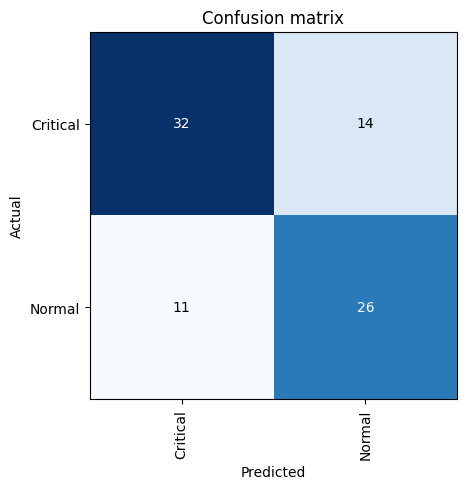

In [53]:
interp = ClassificationInterpretation.from_learner(learn)
interp.plot_confusion_matrix()

## Resnet50

In [54]:

# Step 3: Load a   ResNet18 Model
learn = cnn_learner(dls, resnet50, metrics=accuracy)

# Step 4: Train the Model
learn.fit_one_cycle(25)

c:\Python312\Lib\site-packages\fastai\vision\learner.py:301: UserWarning: `cnn_learner` has been renamed to `vision_learner` -- please update your code
  warn("`cnn_learner` has been renamed to `vision_learner` -- please update your code")


epoch,train_loss,valid_loss,accuracy,time
0,1.114861,0.864122,0.433735,00:01
1,1.286245,0.937675,0.518072,00:00
2,1.218691,0.817299,0.602410,00:00
3,1.214561,2.090038,0.542169,00:00
4,1.147596,1.822568,0.542169,00:00
5,1.116315,2.304458,0.530120,00:00
6,1.077612,1.505031,0.409639,00:00
7,1.072149,1.414321,0.469880,00:00
8,1.050140,16.353968,0.445783,00:00
9,1.034792,36.410763,0.445783,00:00


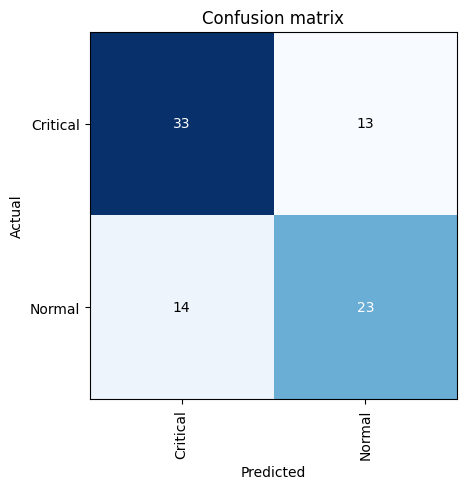

In [55]:
interp = ClassificationInterpretation.from_learner(learn)
interp.plot_confusion_matrix()

##  Resnet101

In [56]:

# Step 3: Load a Pretrained   Model
learn = cnn_learner(dls, resnet101, metrics=accuracy)

# Step 4: Train the Model
learn.fit_one_cycle(25) 

c:\Python312\Lib\site-packages\fastai\vision\learner.py:301: UserWarning: `cnn_learner` has been renamed to `vision_learner` -- please update your code
  warn("`cnn_learner` has been renamed to `vision_learner` -- please update your code")


epoch,train_loss,valid_loss,accuracy,time
0,1.258904,0.805008,0.481928,00:01
1,1.187518,0.615011,0.626506,00:01
2,1.155461,1.032402,0.481928,00:01
3,1.111475,1.094848,0.469880,00:01
4,1.064175,0.895114,0.493976,00:01
5,1.026431,1.301865,0.409639,00:01
6,0.997506,1.962955,0.493976,00:01
7,0.991267,1.813126,0.566265,00:01
8,0.992722,1.751528,0.518072,00:01
9,0.963363,1.218060,0.638554,00:01


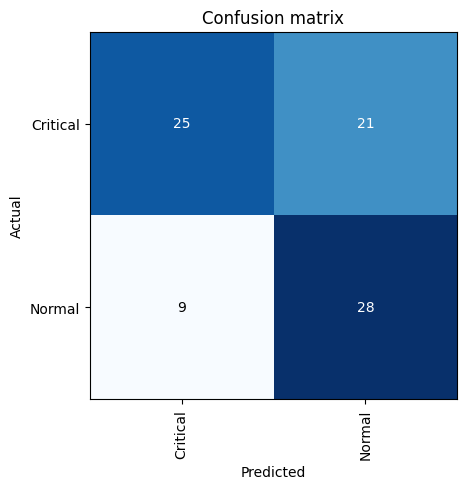

In [57]:
interp = ClassificationInterpretation.from_learner(learn)
interp.plot_confusion_matrix()

## Resnet 152

In [58]:
# Step 3: Load a Pretrained   Model
learn = cnn_learner(dls, resnet152, metrics=accuracy)

# Step 4: Train the Model
learn.fit_one_cycle(25)


c:\Python312\Lib\site-packages\fastai\vision\learner.py:301: UserWarning: `cnn_learner` has been renamed to `vision_learner` -- please update your code
  warn("`cnn_learner` has been renamed to `vision_learner` -- please update your code")


epoch,train_loss,valid_loss,accuracy,time
0,1.231137,1.233655,0.433735,00:01
1,1.259648,0.975235,0.493976,00:01
2,1.170837,1.086890,0.445783,00:01
3,1.134266,0.941641,0.518072,00:01
4,1.140124,2.241413,0.385542,00:01
5,1.103703,4.550839,0.445783,00:01
6,1.098562,3.756281,0.445783,00:01
7,1.089746,2.620774,0.397590,00:01
8,1.102702,3.569770,0.445783,00:01
9,1.092040,4.954783,0.469880,00:01


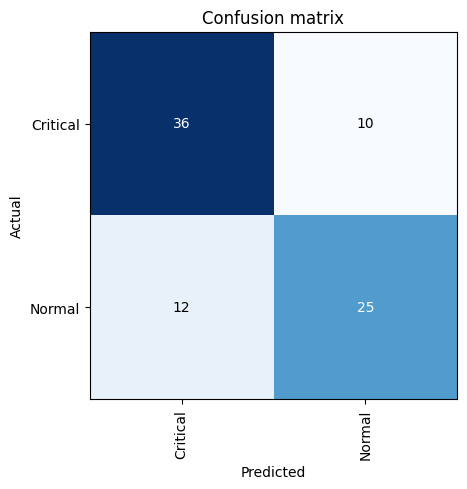

In [59]:

interp = ClassificationInterpretation.from_learner(learn)
interp.plot_confusion_matrix()

# Grad-CAM

In [60]:
from fastai.vision.all import *

# Paso 1: Definir el DataBlock
datablock = DataBlock(
    blocks=(ImageBlock, CategoryBlock), 
    get_items=get_image_files, 
    splitter=RandomSplitter(valid_pct=0.2, seed=42),
    get_y=parent_label,
    item_tfms=Resize(36)  # Redimensionar imágenes a 36x36 si es necesario
)
 

# Obtener las rutas de las imágenes de prueba
test_images_path = 'vfp/img'
test_files = get_image_files(test_images_path)

# Crear el DataLoader de prueba con transformaciones
test_dl = dls.test_dl(test_files, with_labels=True)

# Mapear etiquetas originales con índices
vocab = dls.vocab
index_to_label = {i: label for i, label in enumerate(vocab)}

# Inicializar contadores
total_count = {label: 0 for label in vocab}
correct_count = {label: 0 for label in vocab}
correct_images = {label: [] for label in vocab}

# Evaluar las imágenes correctamente clasificadas
model = learn.model 
preds, targs = learn.get_preds(dl=test_dl)
preds = preds.argmax(dim=1)

for i, (pred, actual) in enumerate(zip(preds, targs)):
    actual_label = index_to_label[actual.item()]
    total_count[actual_label] += 1
    if pred == actual:
        correct_count[actual_label] += 1 
        img = PILImage.create(test_files[i]) 
        correct_images[actual_label].append(img)


print("Correctly classified images:", correct_count)
print("Total images per class:", total_count)

Correctly classified images: {'Critical': 168, 'Normal': 123}
Total images per class: {'Critical': 225, 'Normal': 191}


In [61]:
import torch
import torch.nn.functional as F
import numpy as np

def apply_grad_cam(model, x):
    """
    Apply Grad-CAM to a single image tensor `x` and a `model`.
    
    Args:
    - model: The model to analyze.
    - x: The input tensor of shape (1, C, H, W).
    
    Returns:
    - A heatmap of shape (H, W).
    """
    # Ensure model is in evaluation mode
    model.eval()
    
    # Step 1: Identify the last convolutional layer
    final_conv_layer = None
    for name, module in model.named_modules():
        if isinstance(module, torch.nn.Conv2d):
            final_conv_layer = module
    
    # Safety check
    if final_conv_layer is None:
        raise Exception("No convolutional layer found")
    
    # Step 2: Register hooks
    gradients = []
    def backward_hook(module, grad_in, grad_out):
        gradients.append(grad_out[0])
    
    features = []
    def forward_hook(module, input, output):
        features.append(output)
    
    hook_backward = final_conv_layer.register_backward_hook(backward_hook)
    hook_forward = final_conv_layer.register_forward_hook(forward_hook)
    
    # Step 3: Forward pass
    x = x.to(device)  # Ensure the input tensor is on the same device as the model
    output = model(x)
    score, index = torch.max(output, dim=1)
    
    # Step 4: Backward pass
    model.zero_grad()
    score.backward(retain_graph=True)
    
    # Step 5: Generate heatmap
    gradients = gradients[0]
    features = features[0]
    weights = torch.mean(gradients, axis=(2, 3), keepdim=True)
    
    grad_cam = torch.sum(weights * features, axis=1)[0].cpu().data.numpy()
    grad_cam = np.maximum(grad_cam, 0)  # ReLU
    
    # Normalize the heatmap
    heatmap = grad_cam / np.max(grad_cam)
    
    # Cleanup hooks
    hook_backward.remove()
    hook_forward.remove()
    
    return heatmap

In [62]:
for label in correct_images:
    correct_images[label] = correct_images[label][:10]
    print("Correct images for label:", label, len(correct_images[label]))

Correct images for label: Critical 10
Correct images for label: Normal 10


torch.Size([1, 3, 36, 36])


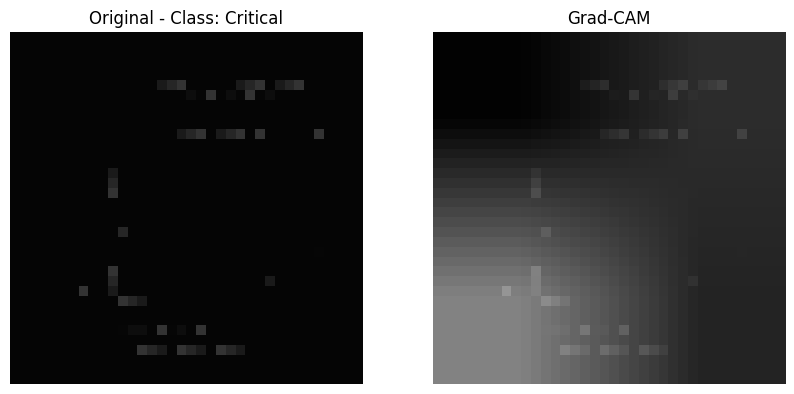

torch.Size([1, 3, 36, 36])


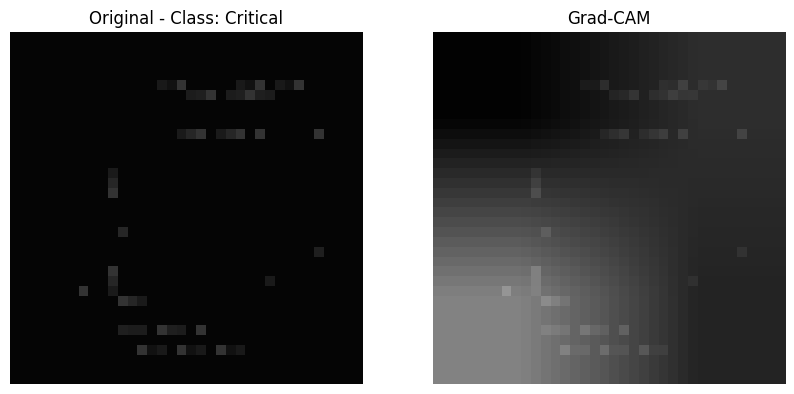

torch.Size([1, 3, 36, 36])


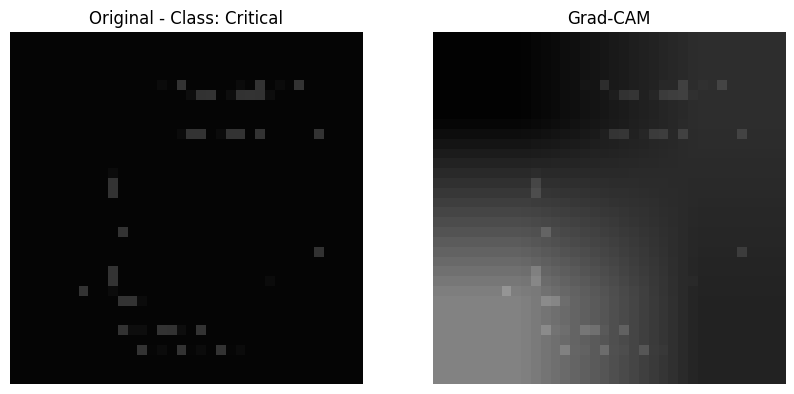

torch.Size([1, 3, 36, 36])


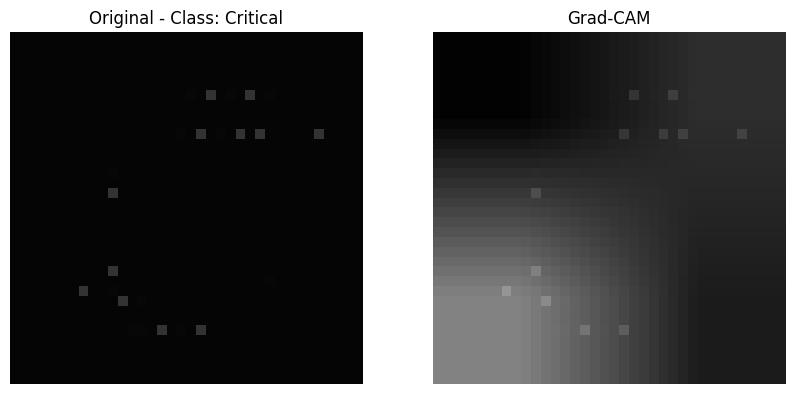

torch.Size([1, 3, 36, 36])


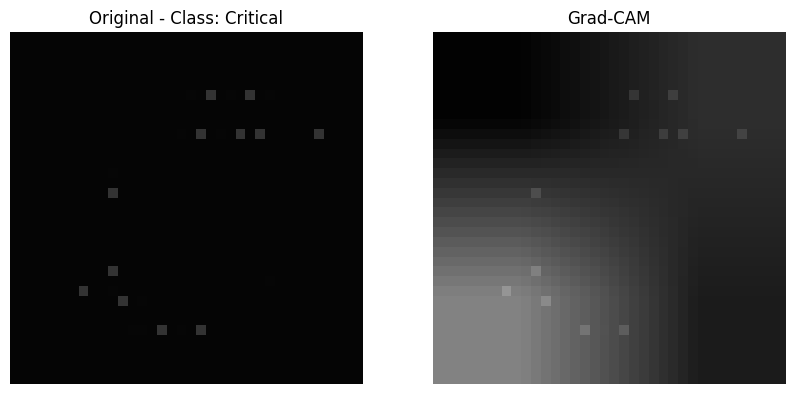

torch.Size([1, 3, 36, 36])


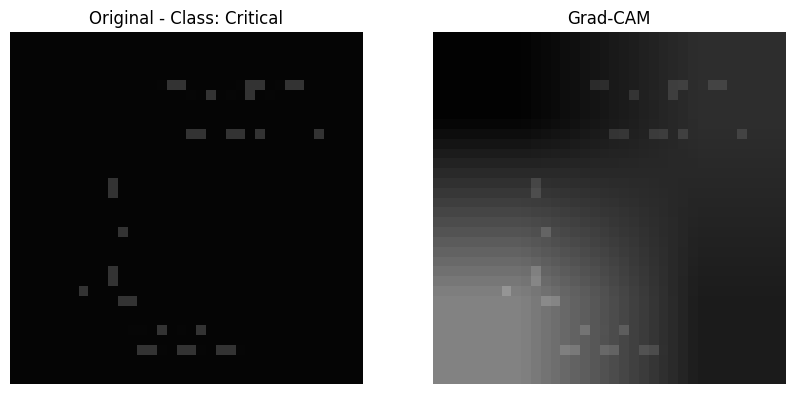

torch.Size([1, 3, 36, 36])


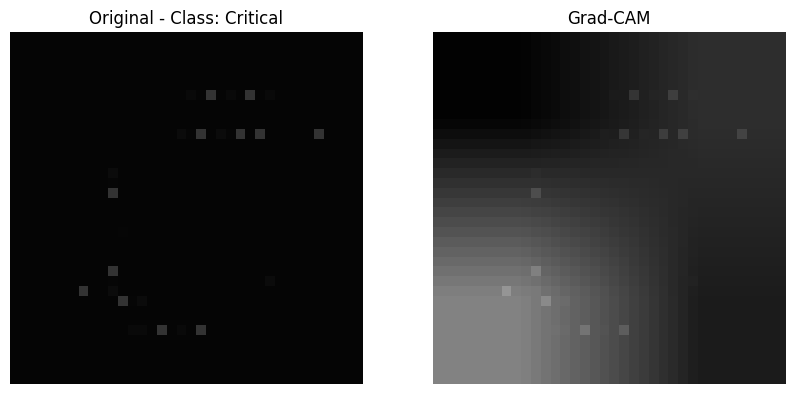

torch.Size([1, 3, 36, 36])


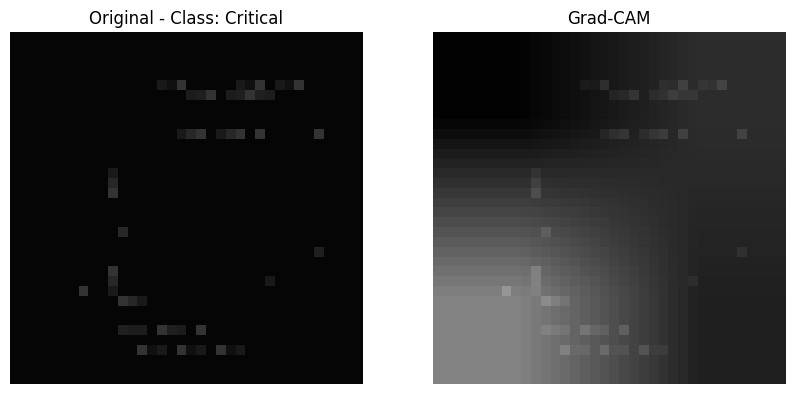

torch.Size([1, 3, 36, 36])


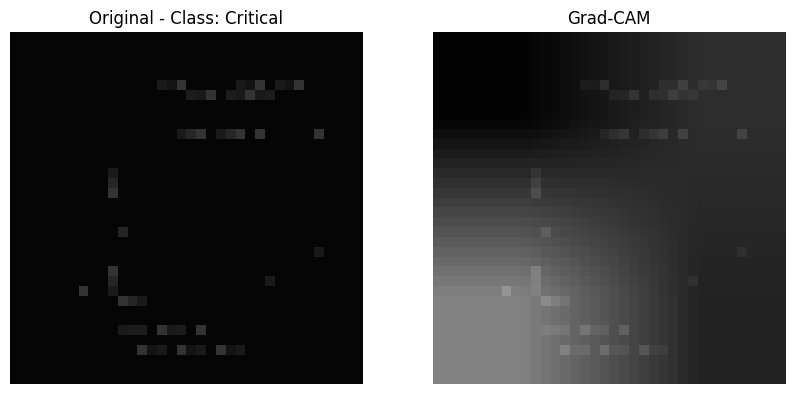

torch.Size([1, 3, 36, 36])


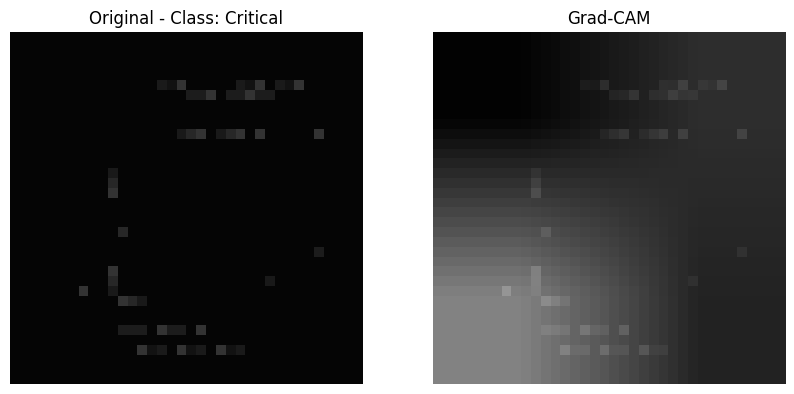

torch.Size([1, 3, 36, 36])


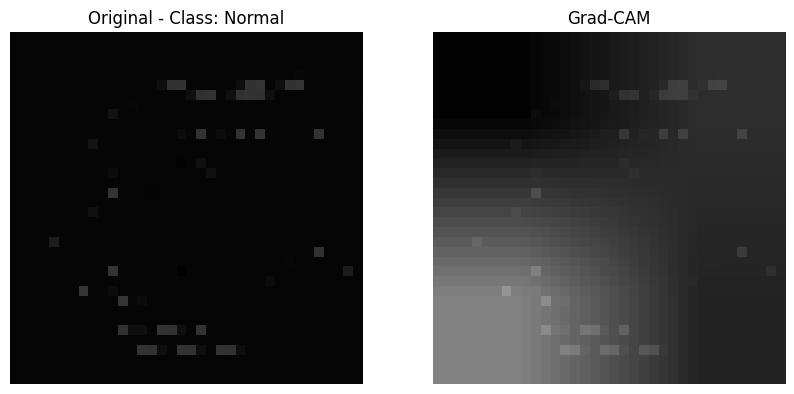

torch.Size([1, 3, 36, 36])


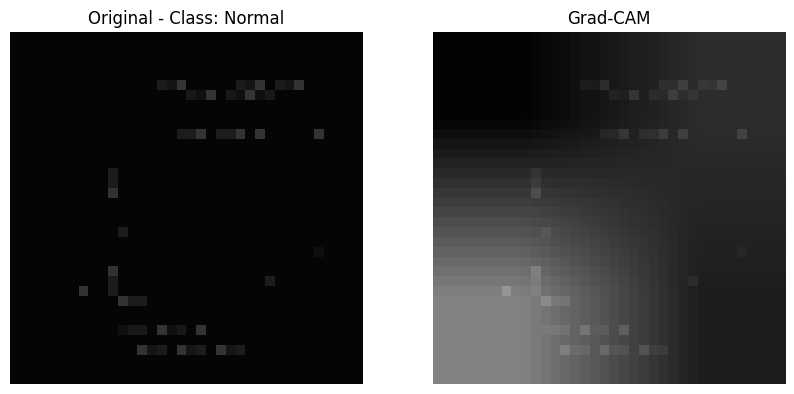

torch.Size([1, 3, 36, 36])


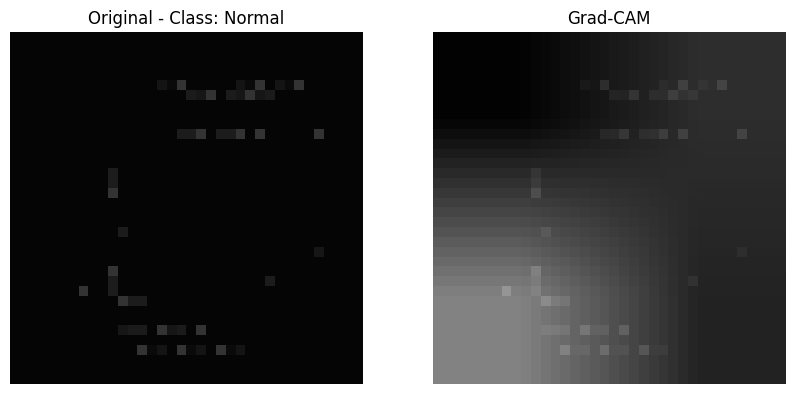

torch.Size([1, 3, 36, 36])


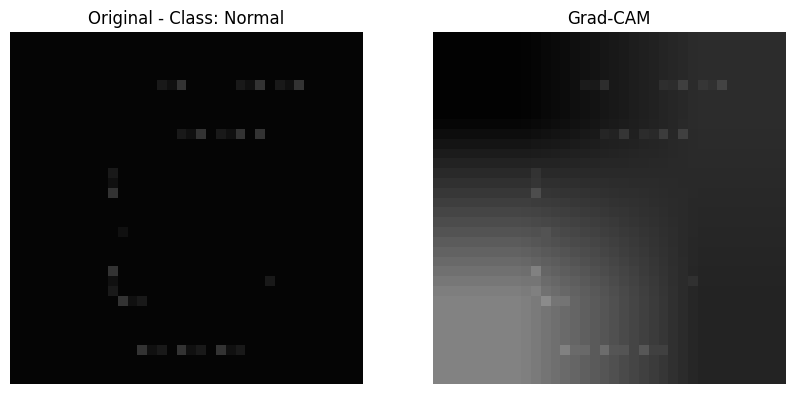

torch.Size([1, 3, 36, 36])


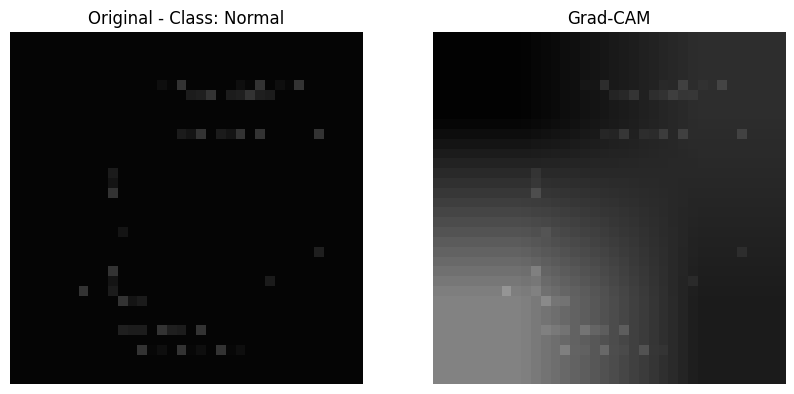

torch.Size([1, 3, 36, 36])


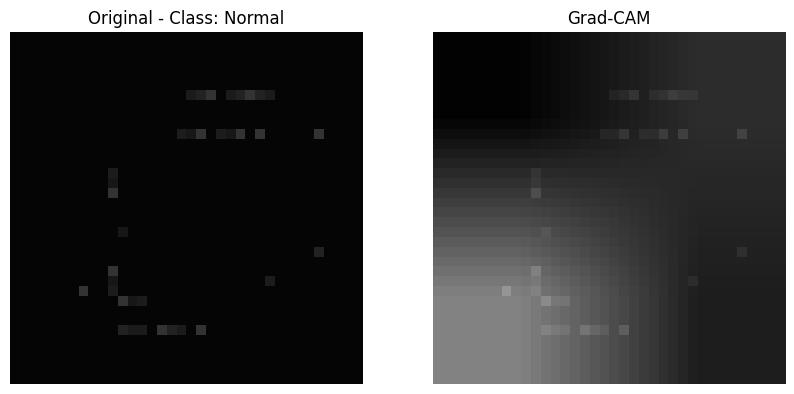

torch.Size([1, 3, 36, 36])


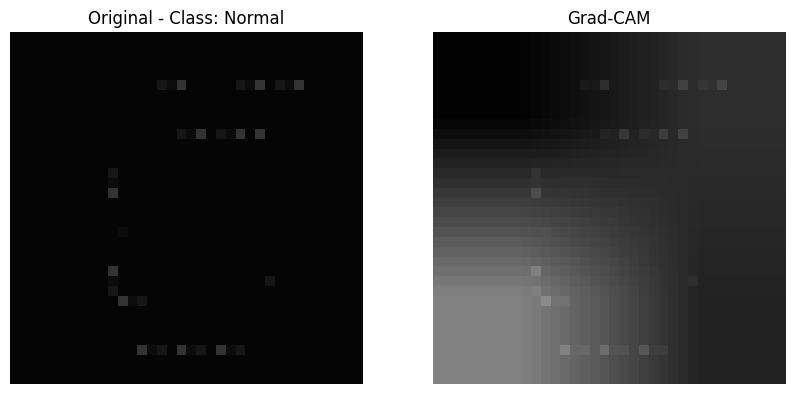

torch.Size([1, 3, 36, 36])


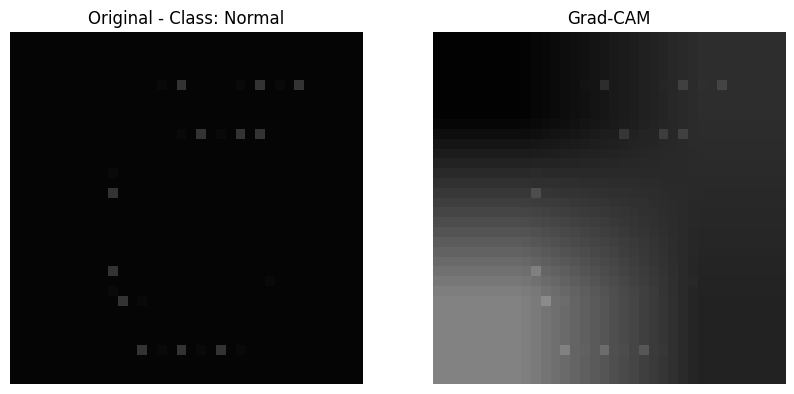

torch.Size([1, 3, 36, 36])


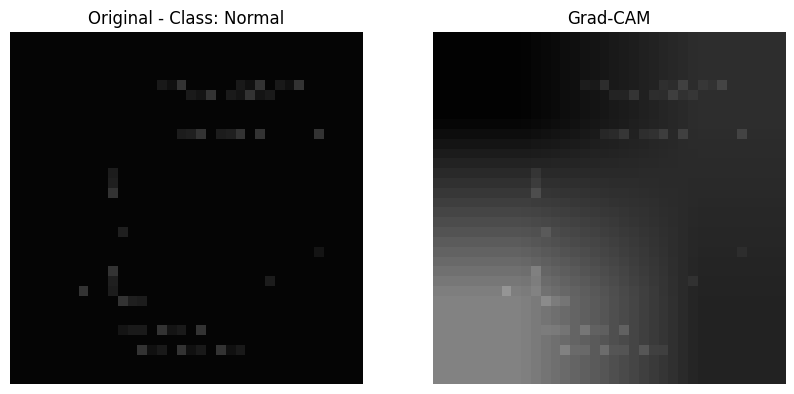

torch.Size([1, 3, 36, 36])


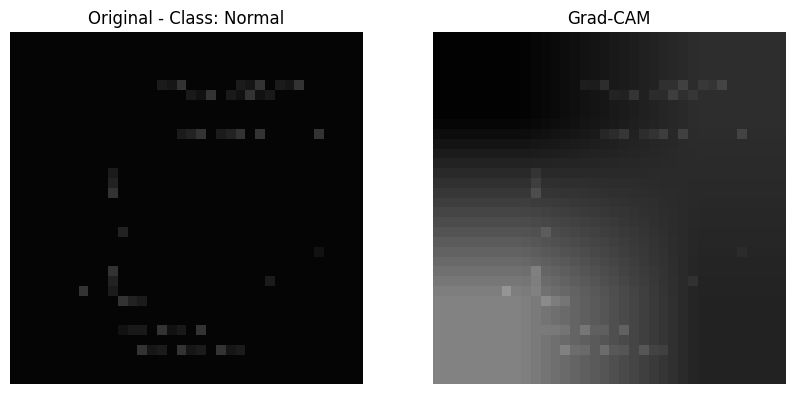

In [64]:
import matplotlib.pyplot as plt
import numpy as np
import torchvision.transforms as T
import cv2
 
# Function to convert tensor image to numpy for plotting
def tensor_to_numpy(tensor_img):
    # Convert PyTorch tensor to numpy array
    return np.array(tensor_img)
 

def overlay_heatmap(image, heatmap):
    heatmap_resized = cv2.resize(heatmap, (image.shape[1], image.shape[0]))  # Redimensionar heatmap
    if len(image.shape) == 3 and image.shape[2] == 3:
        heatmap_resized = np.stack([heatmap_resized]*3, axis=-1)  # Duplicar canal si es necesario
    # Normalizar la imagen y el heatmap para estar en el rango [0, 1]
    image = image / 255.0 if image.max() > 1 else image
    heatmap_resized = heatmap_resized / np.max(heatmap_resized)
    return image * 0.5 + heatmap_resized * 0.5

# Plotting the images with labels and heatmaps
for label, images in correct_images.items():
    for image_tensor in images:         
        image_np = tensor_to_numpy(image_tensor)
        image_tensor = T.ToTensor()(image_tensor).unsqueeze(0)
        print(image_tensor.shape)
        heatmap = apply_grad_cam(model, image_tensor)
        
        overlayed_image = overlay_heatmap(image_np, heatmap)
        
        # Plotting
        plt.figure(figsize=(10, 5))
        plt.subplot(1, 2, 1)
        plt.imshow(image_np)
        plt.title(f'Original - Class: {label}')
        plt.axis('off')
        
        plt.subplot(1, 2, 2)
        plt.imshow(overlayed_image)
        plt.title(f'Grad-CAM')
        plt.axis('off')
        
        plt.show()